<a href="https://colab.research.google.com/github/Sandebrasque/Code-Program-Tugas-Besar-Sistem-Kendali-Mekanika/blob/main/Tugas_Besar_AI_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

                DETEKSI BERITA HOAX DENGAN NAIVE BAYES                


,Label,Berita
0,0,Donald Trump Sends Out Embarrassing New Year’s...
1,1,"As U.S. budget fight looms, Republicans flip t..."
2,0,Drunk Bragging By Trump Staffer Started Russia...
3,1,U.S. military to accept transgender recruits o...
4,0,Sheriff David Clarke Becomes An Internet Joke ...



Jumlah data: 200

Nama kolom: ['Label', 'Berita']

LANGKAH 1: Preprocessing Data
----------------------------------------------------------------------
Distribusi kelas (Target Output):
Label
0    100
1    100
Name: count, dtype: int64
(0 = Hoax/Fake News, 1 = Berita Asli/True News)

LANGKAH 2: Ekstraksi Fitur Teks (TF-IDF)
----------------------------------------------------------------------
Dimensi Vektor TF-IDF (Baris, Kata Unik): (200, 951)

LANGKAH 3: Split Dataset (Train-Test Split)
----------------------------------------------------------------------
Rasio Split = 80:20
Data Training: 160
Data Testing: 40

LANGKAH 4: Training Model Naive Bayes
----------------------------------------------------------------------
Model Naive Bayes berhasil dilatih menggunakan data training.

LANGKAH 5: Evaluasi Model pada Data Uji
----------------------------------------------------------------------
Akurasi Model: 0.625

Classification Report (Recall, Precision, F1-Score):
              prec

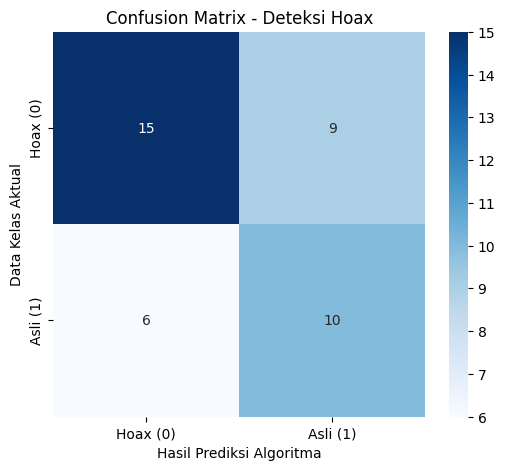


LANGKAH 6: Input Berita Baru & Bedah Rumus Naive Bayes
----------------------------------------------------------------------
Masukkan judul/teks berita baru (misal copy dari dataset asli):
Exclusive: Trump administration considers toughening visa screening

------------------------------------------------------------
BEDAH RUMUS: Perhitungan Probabilitas Kemunculan Kata (Likelihood)
------------------------------------------------------------

Kata 'administration':
P(kata|Hoax) = (0.72+1)/(211.28+951) = 0.001484
P(kata|Asli) = (2.64+1)/(231.80+951) = 0.003075

Kata 'considers':
P(kata|Hoax) = (0.00+1)/(211.28+951) = 0.000860
P(kata|Asli) = (0.36+1)/(231.80+951) = 0.001147

Kata 'exclusive':
P(kata|Hoax) = (0.00+1)/(211.28+951) = 0.000860
P(kata|Asli) = (0.00+1)/(231.80+951) = 0.000845

Kata 'screening':
P(kata|Hoax) = (0.00+1)/(211.28+951) = 0.000860
P(kata|Asli) = (0.00+1)/(231.80+951) = 0.000845

Kata 'toughening':
P(kata|Hoax) = (0.00+1)/(211.28+951) = 0.000860
P(kata|Asli) = (0.

In [1]:
# -*- coding: utf-8 -*-
"""
PROGRAM TUGAS BESAR - KELAS PENGENALAN POLA
DETEKSI BERITA HOAX DENGAN NAIVE BAYES
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ================= HEADER =================
def display_header(title):
    print("=" * 70)
    print(title.center(70))
    print("=" * 70)

def display_step(step):
    print("\n" + step)
    print("-" * 70)

display_header("DETEKSI BERITA HOAX DENGAN NAIVE BAYES")

# ================= LOAD DATASET =================
def load_dataset():

    sheet_url = "https://docs.google.com/spreadsheets/d/1n4_7sdithB212FqAVGaRxlmvqWbeZmO7m9vac5Dau9Q/edit?gid=0#gid=0"

    url = sheet_url.replace('/edit', '/export').replace('?', '?format=csv&')

    try:
        df = pd.read_csv(url)
        return df
    except Exception as e:
        print("Gagal memuat data. Pastikan link benar.")
        print(f"Error: {e}")
        return None

df = load_dataset()

if df is not None:
    display(df.head())
    print("\nJumlah data:", len(df))
    print("\nNama kolom:", df.columns.tolist())

    # ================= PREPROCESSING =================
    display_step("LANGKAH 1: Preprocessing Data")

    if 'Label' not in df.columns or 'Berita' not in df.columns:
        print("Error: Kolom 'Label' atau 'Berita' tidak ditemukan dalam dataset.")
    else:
        df['Berita'] = df['Berita'].astype(str)

        df = df.dropna(subset=['Label', 'Berita'])

        X = df['Berita']
        y = df['Label'].astype(int)

        print("Distribusi kelas (Target Output):")
        print(y.value_counts())
        print("(0 = Hoax/Fake News, 1 = Berita Asli/True News)")

        # ================= TF-IDF =================
        display_step("LANGKAH 2: Ekstraksi Fitur Teks (TF-IDF)")

        tfidf = TfidfVectorizer(
            lowercase=True,
            stop_words='english',
            max_features=3000
        )

        X_tfidf = tfidf.fit_transform(X)
        print("Dimensi Vektor TF-IDF (Baris, Kata Unik):", X_tfidf.shape)

        # ================= SPLIT DATA =================
        display_step("LANGKAH 3: Split Dataset (Train-Test Split)")

        X_train, X_test, y_train, y_test = train_test_split(
            X_tfidf, y, test_size=0.2, random_state=42
        )
        print("Rasio Split = 80:20")
        print("Data Training:", X_train.shape[0])
        print("Data Testing:", X_test.shape[0])

        # ================= TRAINING =================
        display_step("LANGKAH 4: Training Model Naive Bayes")

        model = MultinomialNB()
        model.fit(X_train, y_train)
        print("Model Naive Bayes berhasil dilatih menggunakan data training.")

        # ================= EVALUASI =================
        display_step("LANGKAH 5: Evaluasi Model pada Data Uji")

        y_pred = model.predict(X_test)

        print("Akurasi Model:", accuracy_score(y_test, y_pred))
        print("\nClassification Report (Recall, Precision, F1-Score):")
        print(classification_report(y_test, y_pred))

        cm = confusion_matrix(y_test, y_pred)

        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Hoax (0)', 'Asli (1)'],
                    yticklabels=['Hoax (0)', 'Asli (1)'])
        plt.xlabel("Hasil Prediksi Algoritma")
        plt.ylabel("Data Kelas Aktual")
        plt.title("Confusion Matrix - Deteksi Hoax")
        plt.show()

        # ================= UJI INPUT BERITA BARU & BEDAH RUMUS =================
        display_step("LANGKAH 6: Input Berita Baru & Bedah Rumus Naive Bayes")

        berita_baru = input("Masukkan judul/teks berita baru (misal copy dari dataset asli):\n")

        berita_vec = tfidf.transform([berita_baru])

        prediksi = model.predict(berita_vec)
        probabilitas = model.predict_proba(berita_vec)

        # --- TAMPILAN PERHITUNGAN MANUAL (BEDAH RUMUS KELAS) ---
        print("\n" + "-"*60)
        print("BEDAH RUMUS: Perhitungan Probabilitas Kemunculan Kata (Likelihood)")
        print("-" * 60)

        feature_names = tfidf.get_feature_names_out()

        total_weight_hoax = model.feature_count_[0].sum()
        total_weight_asli = model.feature_count_[1].sum()
        vocab_count = len(feature_names)

        sorted_indices = berita_vec.indices

        if len(sorted_indices) == 0:
            print("Peringatan: Tidak ada kata dari input yang dikenali oleh model training.")
        else:
            for idx in sorted_indices:
                word = feature_names[idx]

                count_in_hoax = model.feature_count_[0][idx]
                count_in_asli = model.feature_count_[1][idx]

                prob_hoax = (count_in_hoax + 1) / (total_weight_hoax + vocab_count)
                prob_asli = (count_in_asli + 1) / (total_weight_asli + vocab_count)

                print(f"\nKata '{word}':")
                print(f"P(kata|Hoax) = ({count_in_hoax:.2f}+1)/({total_weight_hoax:.2f}+{vocab_count}) = {prob_hoax:.6f}")
                print(f"P(kata|Asli) = ({count_in_asli:.2f}+1)/({total_weight_asli:.2f}+{vocab_count}) = {prob_asli:.6f}")

        print("\n" + "-"*60)
        print("BEDAH RUMUS: Keputusan Log Probabilitas (Prior & Posterior)")
        print("-" * 60)

        prior_hoax = model.class_log_prior_[0]
        prior_asli = model.class_log_prior_[1]

        log_prob_hoax_total = prior_hoax + (berita_vec * model.feature_log_prob_[0].T)[0]
        log_prob_asli_total = prior_asli + (berita_vec * model.feature_log_prob_[1].T)[0]

        print(f"log P(Hoax|Teks Berita) = {log_prob_hoax_total:.5f}")
        print(f"log P(Asli|Teks Berita) = {log_prob_asli_total:.5f}")

        # --- TAMPILAN PROBABILITAS AKHIR (PERSENTASE SOFTMAX) ---
        print("\n" + "-"*60)
        print("Probabilitas Final Prediksi:")

        print(f"Hoax (0): {probabilitas[0][0] * 100:.2f}%")
        print(f"Asli (1): {probabilitas[0][1] * 100:.2f}%")

        print("\n===== HASIL KEPUTUSAN =====")
        if prediksi[0] == 0:
            print("❌ BERITA INI TERINDIKASI HOAX/PALSU ❌")
        else:
            print("✅ BERITA INI TERKLASIFIKASI ASLI/TRUE ✅")

        print("=" * 70)